# Evaluación y Validación de Modelos para Predicción de Diabetes

Comparación de Regresión Logística, Random Forest y SVM utilizando el Diabetes Prediction Dataset.

## 1. Clases y funciones



In [32]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_rel
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

sns.set_style('whitegrid')


In [33]:

class ModelEvaluator:
    def __init__(self, name, model):
        self.name = name
        self.model = model

    def fit(self, X_train, y_train):
        self.model.fit(X_train, y_train)

    def predict(self, X, threshold=0.5):
        p = self.model.predict_proba(X)[:, 1]
        y = (p >= threshold).astype(int)
        return y, p

    def metrics(self, y_true, y_pred, y_prob):
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        return {
            'Model': self.name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
            'ROC_AUC': roc_auc_score(y_true, y_prob),
            'Specificity': tn / (tn + fp)
        }

    def find_best_threshold(self, y_true, proba):
        best = (0.5, 0)
        for t in np.arange(.1, .95, .01):
            score = f1_score(y_true, (proba >= t).astype(int))
            if score > best[1]:
                best = (t, score)
        return best


## 2. Dataset - Diabetes Prediction Dataset.

El Dataset utilizado para realizar la comparativa se tomó del Dataset público de Kaggle con Licencia Data files © Original Authors. El dataset se puede descargar de la [liga](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset)

Para realizar la descarga desde un entorno Python se puede usar el código:

```
import kagglehub
# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
print("Path to dataset files:", path)
```

La estructura del Dataset es la siguiente:

In [34]:
df = pd.read_csv('../data/diabetes_prediction_dataset.csv')
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 3. Separación Datos de prueba y selección de modelos a probar.

Para comenzar con el entrenamiento, primero es necesario seleccionar los datos que se usarán para el entrenamiento, así como los campos que se usarán como objetivo y cuales para identificar patrones dentro de los modelos.

Una vez identificados los campos a utilizar se realizan los ajustes para estandarizar los datos y normalizarlos de tal manera que todos queden dentro de una escala adecuada, así como de solo usar datos que se puedan procesar con el modelo.

Posteriormente, se seleccionarán los modelos de ML que se utilizarán para realizar el comparativo:

- LogisticRegression
- RandomForest
- SVM
- Baseline


In [35]:

TARGET = 'diabetes'
X = df.drop(columns=[TARGET])
y = df[TARGET]

cat = X.select_dtypes(include=['object', 'str']).columns.tolist()
num = [c for c in X.columns if c not in cat]

prep = ColumnTransformer([
    ('num', StandardScaler(), num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat)
])

models = {
    'LogisticRegression': Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=3000))]),
    'RandomForest': Pipeline([('prep', prep), ('clf', RandomForestClassifier(n_estimators=300, random_state=42))]),
    'SVM': Pipeline([('prep', prep), ('clf', CalibratedClassifierCV(SVC(), ensemble=False))]),
    'Baseline': Pipeline([('prep', prep), ('clf', DummyClassifier(strategy='most_frequent'))])
}

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


## 4. Experimentación

Se inicializa el entrenamiento y la experimentación con cada uno de los modelos; se recuperan métricas para el cálculo de curva ROC y el cálculo de AUC.


In [36]:

results = []
artifacts = {}
for name, pipe in models.items():
    ev = ModelEvaluator(name, pipe)
    ev.fit(X_train, y_train)
    pred, prob = ev.predict(X_test)
    m = ev.metrics(y_test, pred, prob)
    scoring = {
        'accuracy': 'accuracy',  # Las métricas como accuracy no generan division zero
        'prec': make_scorer(precision_score, average='macro', zero_division=0),
        'f1': make_scorer(f1_score, average='macro', zero_division=0),
        'roc_auc': 'roc_auc',
        'recall': make_scorer(recall_score, average='macro', zero_division=0),
    }
    cv = cross_validate(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                        scoring=scoring
                        )

    m['CV_ROC_AUC_MEAN'] = cv['test_roc_auc'].mean()
    m['CV_ROC_AUC_STD'] = cv['test_roc_auc'].std()

    results.append(m)
    artifacts[name] = {'pred': pred, 'prob': prob, 'cv': cv}

results_df = pd.DataFrame(results).sort_values('ROC_AUC', ascending=False)
results_df


/Users/miguelgarciavidal/miniforge3/envs/gestion-proyectos-ia/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Specificity,CV_ROC_AUC_MEAN,CV_ROC_AUC_STD
1,RandomForest,0.97020,0.940895,0.692941,0.798103,0.963384,0.995956,0.963238,0.002105
0,LogisticRegression,0.96045,0.858721,0.640000,0.733401,0.962500,0.990219,0.961792,0.001300
2,SVM,0.96585,0.930567,0.646471,0.762930,0.933752,0.995519,0.932149,0.002057
3,Baseline,0.91500,0.000000,0.000000,0.000000,0.500000,1.000000,0.500000,0.000000


## 5. Matriz de Confusión

Se realiza un comparativo entre los modelos a través de us Matriz de confusión para validar los falsos positivos y falsos negativos que arroja cada uno de los modelos.

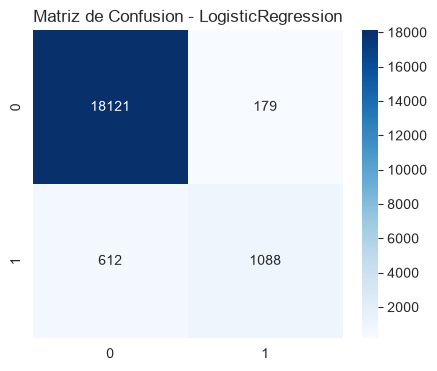

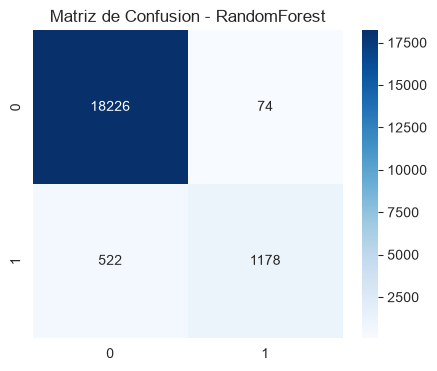

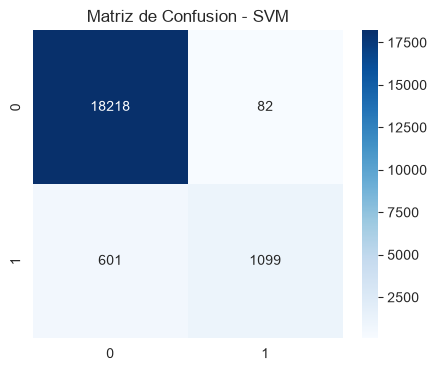

In [37]:

for model in ['LogisticRegression', 'RandomForest', 'SVM']:
    cm = confusion_matrix(y_test, artifacts[model]['pred'])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Matriz de Confusion - {model}')
    plt.show()


## 6. ROC-AUC

Del mismo modo se muestra la gráfica ROC-AUC para comparar cada uno de los modelos.

Como se puede observar los modelos de Logistic Regression y Random Forest obtuvieron un mayor puntaje.

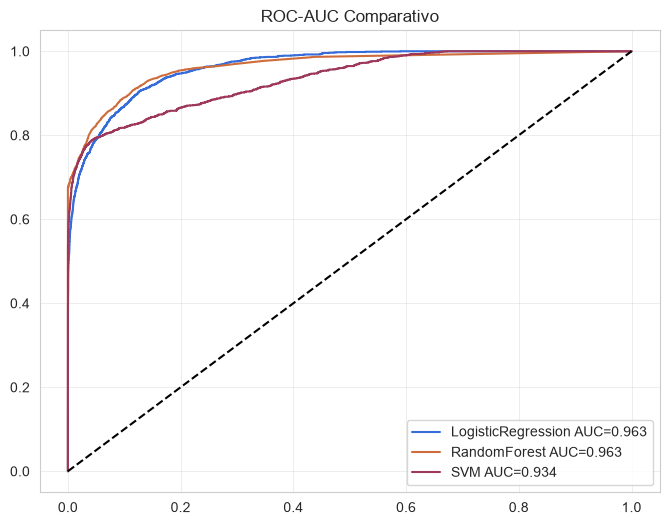

In [38]:

plt.figure(figsize=(8, 6))
for model in ['LogisticRegression', 'RandomForest', 'SVM']:
    p = artifacts[model]['prob']
    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)
    plt.plot(fpr, tpr, label=f'{model} AUC={auc:.3f}')

plt.plot([0, 1], [0, 1], 'k--')
plt.legend()
plt.title('ROC-AUC Comparativo')
plt.show()


## 7. Prueba A/B

Para la comparación entre modelos se hará uso de pruebas A/B entre los modelos:

- RandomForest
- SVM
- LogisticRegression


In [39]:

rf = artifacts['RandomForest']['cv']['test_roc_auc']
svm = artifacts['SVM']['cv']['test_roc_auc']
stat, pvalue = ttest_rel(rf, svm)
print('A/B Test RandomForest vs SVM')
print('t=', stat)
print('p-value=', pvalue)


A/B Test RandomForest vs SVM
t= 20.9772469537342
p-value= 3.0521524854458283e-05


In [40]:

lr = artifacts['LogisticRegression']['cv']['test_roc_auc']
stat2, p_value2 = ttest_rel(rf, lr)
print('A/B Test RandomForest vs LogisticRegression')
print('t=', stat2)
print('p-value=', p_value2)


A/B Test RandomForest vs LogisticRegression
t= 1.8581441570109003
p-value= 0.13669385596141223


In [41]:
stat3, p_value3 = ttest_rel(lr, svm)
print('A/B Test LogisticRegression vs SVM')
print('t=', stat3)
print('p-value=', p_value3)

A/B Test LogisticRegression vs SVM
t= 20.905876311974364
p-value= 3.093727614688349e-05


## 8. Tablero

Se presentan los resultados de la comparación de los 3 modelos a través de un tablero en donde se muestran:

- Métricas comparativas:
    -  Accuracy
    - Precision
    - Recall
    - F1-score
- ROC_AUC
- Media ROC_AUC
- Tabla comparativa de métricas


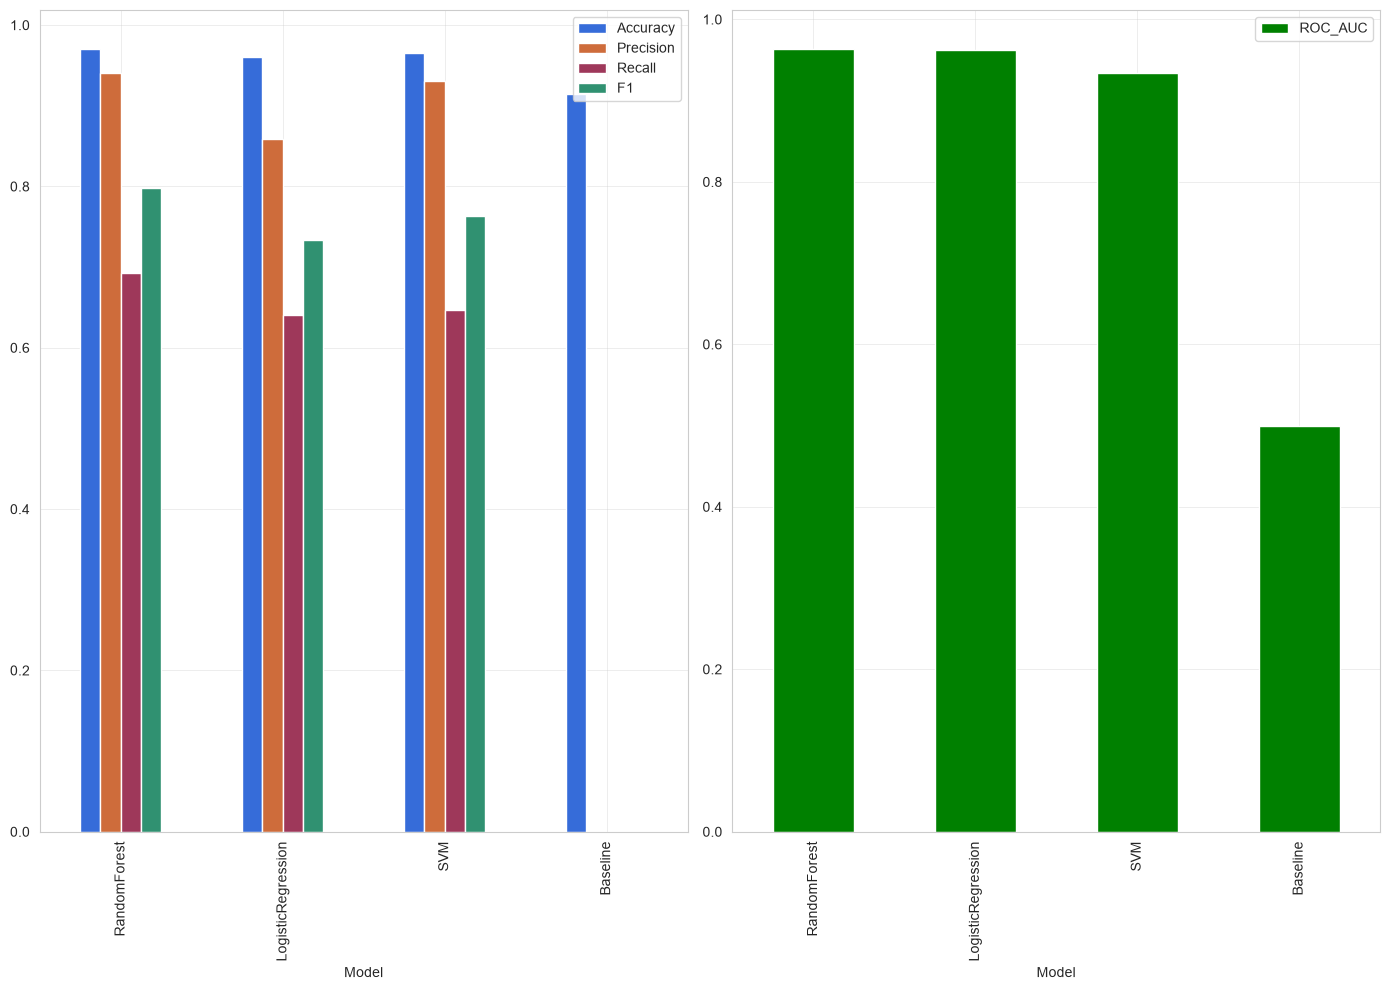

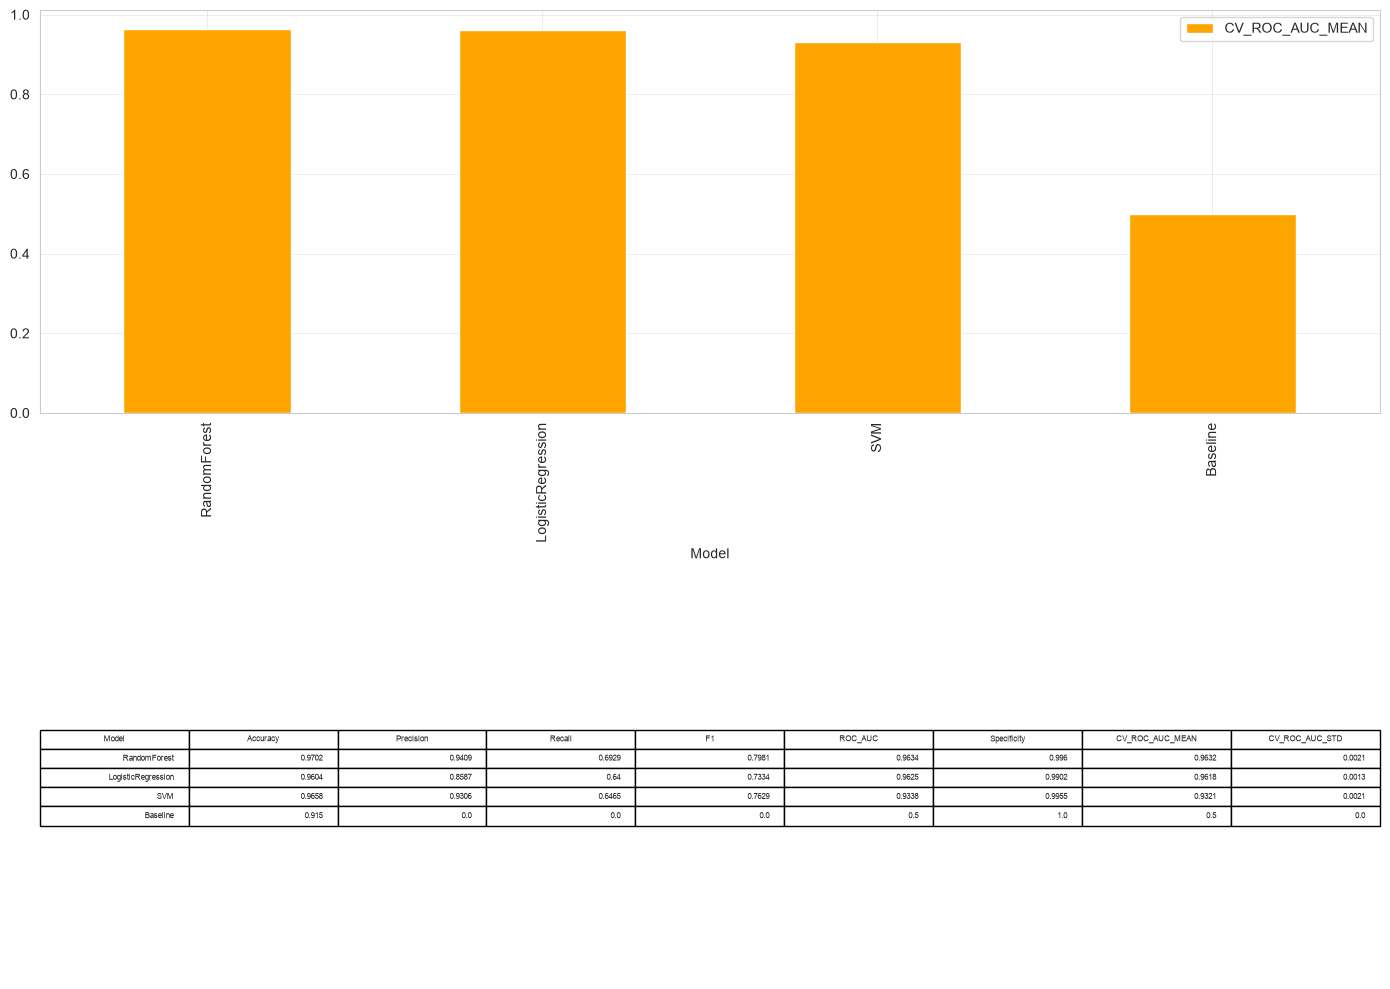

In [42]:
table_df = results_df.copy()
numeric_cols = table_df.select_dtypes(include=np.number).columns
table_df[numeric_cols] = table_df[numeric_cols].round(4)

fig, ax = plt.subplots(1, 2, figsize=(14, 10))
results_df.plot(x='Model', y=['Accuracy', 'Precision', 'Recall', 'F1'], kind='bar', ax=ax[0])
results_df.plot(x='Model', y='ROC_AUC', kind='bar', ax=ax[1], color='green')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 1, figsize=(14, 10))
results_df.plot(x='Model', y='CV_ROC_AUC_MEAN', kind='bar', ax=ax[0], color='orange')
ax[1].axis('off')
ax[1].table(
    cellText=table_df.values,
    colLabels=table_df.columns,
    loc='center'
)
plt.tight_layout()
plt.show()



## 9. Selección del mejor modelo.

Para determinar el mejor modelo se hace una comparativa entre la métrica F1-Score de cada modelo ya que esta es la métrica que mejor balance tiene entre los resultados. Además se calcula el umbral de cada modelo  para definir cual es el mejor modelo.

In [43]:

best_model = results_df.iloc[0]['Model']
proba = artifacts[best_model]['prob']
ev = ModelEvaluator(best_model, None)
threshold, best_f1 = ev.find_best_threshold(y_test, proba)
print('Modelo:', best_model)
print('Mejor umbral:', threshold)
print('F1:', best_f1)


Modelo: RandomForest
Mejor umbral: 0.7099999999999997
F1: 0.8061797752808989


## Interpretación de Negocio

- Los falsos negativos son críticos porque pacientes con diabetes podrían no ser detectados.
- Recall suele ser una métrica prioritaria.
- ROC-AUC y validación cruzada ayudan a evaluar estabilidad.
- El mejor modelo debe equilibrar desempeño estadístico e impacto en negocio.